# 02 · Baselines, modelo global y backtest (h = 4)

Fases 2–3 de DECISIONES.md. Features documentados en `reports/FEATURES.md`; diseño del backtest en LOG_DECISIONES #19.

- **Validación** (objetivos sep-2024 → ago-2025): hiperparámetros, ablaciones de features y ruta por segmento.
- **Prueba** (objetivos sep-2025 → sep-2026): solo se evalúa lo elegido en validación. ⚠️ Cae en el nivel bajo
  posterior al escalón de 2024 (§13: el test es un periodo anómalo).
- Métricas: MASE y RMSSE frente al seasonal-naive (s = 12), relMAE, WAPE, sesgo y MAPE (solo referencia,
  sobre y > 0). Las métricas `_total` suman los SKUs por mes (vista de compras).

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from estilo import aplicar, COLORES, AZUL, GRIS, GRIS_CLARO, FMT_MILES
from metricas import resumen

aplicar()
pd.set_option("display.width", 200, "display.max_columns", 40)
RES = RAIZ / "data" / "processed" / "resultados"
FIG = RAIZ / "reports" / "figuras"
val = pd.read_parquet(RES / "pronosticos_validacion.parquet")
test = pd.read_parquet(RES / "pronosticos_prueba.parquet")
meta = json.loads((RES / "meta.json").read_text(encoding="utf-8"))
cob = pd.read_csv(RES / "cobertura.csv", parse_dates=["mes_obj"])
clas = pd.read_parquet(RAIZ / "data" / "processed" / "clasificacion_sku.parquet")[["id_articulo", "abc", "xyz"]]

CLASICOS = ["Naive", "SNaive", "MA12", "ETS", "SARIMA_fam", "Croston", "SBA", "TSB", "Ruta_clasica"]
ML = [c for c in val.columns if c.startswith("ML_")]
FMT = {"MASE": "{:.3f}", "RMSSE": "{:.3f}", "WAPE": "{:.1%}", "relMAE": "{:.3f}", "sesgo": "{:+.1%}",
       "MAPE_y>0": "{:.0%}", "WAPE_total": "{:.1%}", "sesgo_total": "{:+.1%}"}
def tabla(df, modelos):
    return resumen(df, modelos).sort_values("MASE").style.format(FMT)

## 1. Set evaluado y cobertura

In [2]:
for n, d in [("validación", val), ("prueba", test)]:
    print(f"{n}: {len(d):,} pares SKU-origen · {d.id_articulo.nunique():,} SKUs · {d.origen.nunique()} orígenes · "
          f"{d.y.sum():,.0f} u. reales")
cob["pct_fuera"] = cob.u_fuera_set / cob.u_total
print(f"Unidades del mes objetivo fuera del set (SKUs con < 13 meses o nacidos después del origen): "
      f"mediana {cob.pct_fuera.median():.1%}, rango {cob.pct_fuera.min():.1%}–{cob.pct_fuera.max():.1%}")
print("Clases SB en prueba:", test.clase.value_counts().to_dict())

validación: 9,345 pares SKU-origen · 876 SKUs · 12 orígenes · 1,333,525 u. reales
prueba: 10,231 pares SKU-origen · 919 SKUs · 13 orígenes · 1,420,057 u. reales
Unidades del mes objetivo fuera del set (SKUs con < 13 meses o nacidos después del origen): mediana 2.2%, rango 1.3%–3.5%
Clases SB en prueba: {'errática': 6031, 'grumosa': 2145, 'suave': 1701, 'intermitente': 354}


## 2. Validación: hiperparámetros del modelo global

In [3]:
print(pd.DataFrame(meta["hiper"]).T[["MASE", "RMSSE", "WAPE", "sesgo"]].round(3).to_string())
print("Elegido:", meta["hiper_elegido"])

    MASE  RMSSE   WAPE  sesgo
A  0.751  0.654  0.460  0.087
B  0.762  0.657  0.449  0.084
C  0.744  0.651  0.461  0.103
Elegido: C


## 3. Validación: todos los modelos

In [4]:
tabla(val, CLASICOS + ML)

,MASE,RMSSE,WAPE,relMAE,sesgo,MAPE_y>0,WAPE_total,sesgo_total
ML_devol,0.739,0.648,46.4%,0.722,+10.1%,192%,24.4%,+10.1%
ML_base,0.744,0.651,46.1%,0.717,+10.3%,192%,24.2%,+10.3%
ML_sin_limpieza,0.748,0.651,46.8%,0.728,+10.9%,195%,24.9%,+10.9%
ML_sobre_sku,0.749,0.650,46.5%,0.723,+10.5%,195%,24.3%,+10.5%
ML_sobre_todo,0.753,0.651,47.8%,0.743,+13.6%,200%,25.7%,+13.6%
ML_sobre_agr,0.761,0.659,47.6%,0.740,+13.4%,203%,25.0%,+13.4%
Ruta_clasica,0.784,0.657,45.6%,0.710,+10.3%,210%,20.3%,+10.3%
TSB,0.788,0.659,46.5%,0.724,+13.7%,212%,22.1%,+13.7%
SARIMA_fam,0.808,0.667,47.2%,0.735,+14.7%,208%,22.8%,+14.7%
MA12,0.814,0.662,47.1%,0.733,+12.5%,203%,23.3%,+12.5%


### 3.1 Ablaciones de features (validación y prueba)

Diferencia frente a `ML_base` (negativo = mejora). **Regla de adopción** (LOG #20): una variante reemplaza a
`ML_base` solo si en **validación** baja el MASE en ≥ 0.01 **y** gana en ≥ 2/3 de los orígenes; si no, gana el
modelo más simple. La prueba solo confirma.

In [5]:
def ablacion(d):
    r = resumen(d, ML)
    return (r - r.loc["ML_base"])[["MASE", "RMSSE", "WAPE", "WAPE_total", "sesgo_total"]]
ab = pd.concat({"validación": ablacion(val), "prueba": ablacion(test)}, axis=1)
print(ab.round(4).to_string())

def por_origen(d, modelos):
    return pd.DataFrame({o: resumen(g, modelos).MASE for o, g in d.groupby("origen")}).T
otros = [m for m in ML if m != "ML_base"] + ["Ruta_clasica"]
for n, d in [("validación", val), ("prueba", test)]:
    po = por_origen(d, ["ML_base"] + otros)
    gana = (po[otros].lt(po.ML_base, axis=0)).sum()
    print(f"\n{n}: orígenes (de {len(po)}) donde cada modelo mejora a ML_base:", gana.to_dict())

po_val = por_origen(val, ML)
dif = resumen(val, ML).MASE - resumen(val, ["ML_base"]).MASE.iloc[0]
gana_val = po_val.lt(po_val.ML_base, axis=0).mean()
adopta = [m for m in ML if m != "ML_base" and dif[m] <= -0.01 and gana_val[m] >= 2 / 3]
mejor_ml = min(adopta, key=lambda m: dif[m]) if adopta else "ML_base"
print("\nVariantes que cumplen la regla:", adopta or "ninguna", "→ modelo final:", mejor_ml)

                validación                                         prueba                                       
                      MASE   RMSSE    WAPE WAPE_total sesgo_total    MASE   RMSSE    WAPE WAPE_total sesgo_total
ML_base             0.0000  0.0000  0.0000     0.0000      0.0000  0.0000  0.0000  0.0000     0.0000      0.0000
ML_sin_limpieza     0.0041  0.0000  0.0068     0.0078      0.0067  0.0062  0.0021  0.0002     0.0100      0.0015
ML_sobre_sku        0.0049 -0.0013  0.0039     0.0017      0.0017  0.0021  0.0002 -0.0037    -0.0009     -0.0038
ML_sobre_agr        0.0174  0.0078  0.0146     0.0083      0.0314 -0.0010 -0.0035 -0.0094    -0.0023     -0.0151
ML_sobre_todo       0.0090 -0.0002  0.0165     0.0154      0.0334 -0.0093 -0.0097 -0.0100    -0.0009     -0.0224
ML_devol           -0.0050 -0.0034  0.0029     0.0023     -0.0014  0.0040 -0.0017 -0.0012     0.0088      0.0004



validación: orígenes (de 12) donde cada modelo mejora a ML_base: {'ML_sin_limpieza': 3, 'ML_sobre_sku': 7, 'ML_sobre_agr': 5, 'ML_sobre_todo': 4, 'ML_devol': 7, 'Ruta_clasica': 2}



prueba: orígenes (de 13) donde cada modelo mejora a ML_base: {'ML_sin_limpieza': 6, 'ML_sobre_sku': 6, 'ML_sobre_agr': 8, 'ML_sobre_todo': 8, 'ML_devol': 8, 'Ruta_clasica': 2}



Variantes que cumplen la regla: ninguna → modelo final: ML_base


### 3.2 Ruta por segmento (clase Syntetos–Boylan en el origen)

In [6]:
print("Ruta elegida en validación (mejor clásico por MASE en cada clase):", meta["ruta"])
seg = pd.concat({c: resumen(g, CLASICOS[:-1] + [mejor_ml]).MASE for c, g in val.groupby("clase")}, axis=1)
print(seg.round(3).to_string())

Ruta elegida en validación (mejor clásico por MASE en cada clase): {'errática': 'TSB', 'grumosa': 'TSB', 'intermitente': 'TSB', 'suave': 'SBA'}


            errática  grumosa  intermitente  suave
Naive          0.930    0.654         0.952  0.912
SNaive         1.071    0.915         1.048  1.058
MA12           0.846    0.721         1.029  0.809
ETS            0.905    0.795         0.930  0.824
SARIMA_fam     0.859    0.700         0.918  0.813
Croston        0.878    0.896         1.517  0.821
SBA            0.854    0.868         1.447  0.792
TSB            0.845    0.698         0.840  0.813
ML_base        0.843    0.595         0.646  0.803


### 3.3 Jerárquico middle-out: familia (nivel × índice) repartida con el ML (`src/jerarquico.py`, LOG #32)

En cada origen, el total de la familia = **nivel** (media desestacionalizada de los últimos k meses) × **índice
estacional** de la familia, con datos ≤ origen. Se reparte entre los SKUs con la cuota histórica (`TD_hist`), con la
cuota del `ML_base` (`TD_ML`) o con volumen = promedio entre nivel × índice y Σ `ML_base` (`TD_mix`). k ∈ {3, 6, 12}
se elige en validación. `SARIMA_fam` (otro top-down, con cuota histórica) va de referencia. Misma regla de adopción.

In [7]:
jer = {n: d.merge(pd.read_parquet(RES / f"pronosticos_{p}_jer.parquet"), on=["id_articulo", "origen", "mes_obj"])
       for n, d, p in [("validación", val, "validacion"), ("prueba", test, "prueba")]}
meta_jer = json.loads((RES / "meta_jer.json").read_text(encoding="utf-8"))
k = meta_jer["k_elegido"]
print("MASE de TD_ML por ventana k (validación):", {c: round(v, 3) for c, v in meta_jer["MASE_por_k"].items()}, "→", k)
JER = ["ML_base", "SARIMA_fam", f"TD_hist_{k}", f"TD_ML_{k}", f"TD_mix_{k}"]
for n, d in jer.items():
    r = resumen(d, JER)
    po = pd.DataFrame({o: resumen(g, JER).MASE for o, g in d.groupby("origen")}).T
    r["gana_a_ML"] = [f"{(po[m] < po.ML_base).sum()}/{len(po)}" if m != "ML_base" else "" for m in JER]
    print(f"\n{n}"); print(r[["MASE", "RMSSE", "WAPE", "sesgo", "WAPE_total", "gana_a_ML"]].round(3).to_string())

# ¿el total de la familia (nivel × índice) es mejor que la suma del ML?
for n, d in jer.items():
    g = d.groupby(["familia", "mes_obj"]).agg(y=("y", "sum"), ML=("ML_base", "sum"), F=(f"F_fam_{k}", "first"),
                                              mix=(f"TD_mix_{k}", "sum"))
    w = {c: (g[c] - g.y).abs().sum() / g.y.sum() for c in ["ML", "F", "mix"]}
    print(f"{n}: WAPE familia-mes → Σ ML {w['ML']:.3f} · nivel × índice {w['F']:.3f} · mix {w['mix']:.3f}")

MASE de TD_ML por ventana k (validación): {'TD_ML_k3': 0.721, 'TD_ML_k6': 0.735, 'TD_ML_k12': 0.756} → k3



validación
             MASE  RMSSE   WAPE  sesgo  WAPE_total gana_a_ML
ML_base     0.744  0.651  0.461  0.103       0.242          
SARIMA_fam  0.808  0.667  0.472  0.147       0.228      1/12
TD_hist_k3  0.739  0.651  0.452  0.027       0.212      6/12
TD_ML_k3    0.721  0.650  0.453  0.027       0.212      7/12
TD_mix_k3   0.726  0.644  0.445  0.065       0.221      9/12



prueba
             MASE  RMSSE   WAPE  sesgo  WAPE_total gana_a_ML
ML_base     0.826  0.779  0.504  0.054       0.113          
SARIMA_fam  0.877  0.804  0.541  0.126       0.139      1/13
TD_hist_k3  0.864  0.809  0.519  0.055       0.138      4/13
TD_ML_k3    0.838  0.793  0.517  0.055       0.138      4/13
TD_mix_k3   0.827  0.781  0.503  0.055       0.106      7/13
validación: WAPE familia-mes → Σ ML 0.296 · nivel × índice 0.292 · mix 0.281
prueba: WAPE familia-mes → Σ ML 0.243 · nivel × índice 0.274 · mix 0.246


## 4. Prueba (sep-2025 → sep-2026)

In [8]:
FINALES = ["Naive", "SNaive", "MA12", "ETS", "SARIMA_fam", "Croston", "SBA", "TSB", "Ruta_clasica", "ML_base", "ML_devol",
           "ML_sobre_todo", mejor_ml]
FINALES = list(dict.fromkeys(FINALES))
tabla(test, FINALES)

,MASE,RMSSE,WAPE,relMAE,sesgo,MAPE_y>0,WAPE_total,sesgo_total
ML_sobre_todo,0.817,0.769,49.4%,0.824,+3.2%,191%,11.2%,+3.2%
ML_base,0.826,0.779,50.4%,0.841,+5.4%,196%,11.3%,+5.4%
ML_devol,0.830,0.777,50.3%,0.839,+5.5%,193%,12.2%,+5.5%
MA12,0.855,0.790,49.9%,0.832,+3.4%,196%,10.7%,+3.4%
SARIMA_fam,0.877,0.804,54.1%,0.904,+12.6%,204%,13.9%,+12.6%
Ruta_clasica,0.882,0.801,50.8%,0.848,+4.2%,212%,11.8%,+4.2%
TSB,0.882,0.800,51.7%,0.863,+7.5%,214%,12.2%,+7.5%
ETS,0.911,0.826,57.5%,0.960,+11.4%,223%,12.9%,+11.4%
SBA,0.948,0.836,50.5%,0.842,+2.4%,206%,11.6%,+2.4%
Croston,0.966,0.842,52.0%,0.869,+7.8%,218%,12.3%,+7.8%


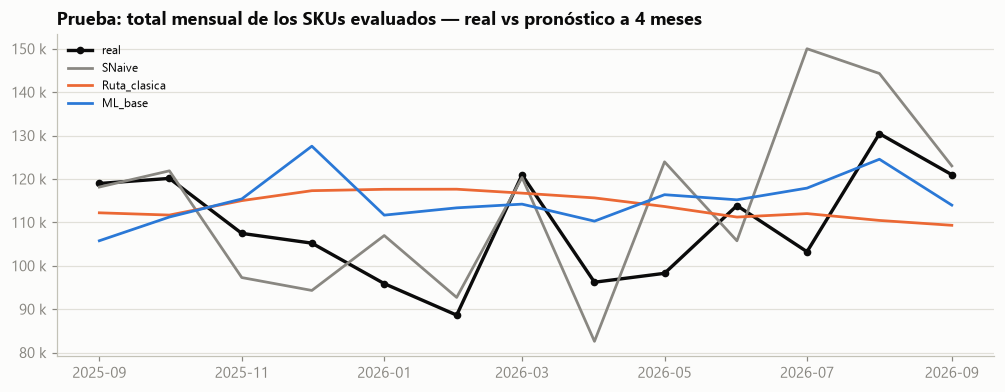

mes_obj        2025-09-01  2025-10-01  2025-11-01  2025-12-01  2026-01-01  2026-02-01  2026-03-01  2026-04-01  2026-05-01  2026-06-01  2026-07-01  2026-08-01  2026-09-01
Naive                 2.6       -13.6        38.0        35.1        25.8        36.1       -10.5        10.2        -1.8       -21.3        18.1       -25.6       -18.2
SNaive               -0.7         1.5        -9.5       -10.4        11.6         4.6        -0.5       -14.2        26.1        -7.1        45.3        10.6         1.7
MA12                 -9.7       -10.4         3.5         6.9        17.9        27.4        -5.5        19.9        16.6         0.5        11.0       -11.1        -5.6
ETS                   2.4        25.5        16.5        24.8        23.0        35.0        -4.0        12.8        16.9        -2.6        13.1        -0.2        -2.5
SARIMA_fam            1.3         6.6         7.5        20.2        31.4        44.8         4.4        28.2        23.4         2.4        20.4     

In [9]:
tot = test.groupby("mes_obj")[["y"] + FINALES].sum()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(tot.index, tot.y, color="#0b0b0b", lw=2.2, marker="o", ms=4, label="real")
for m, col in zip(["SNaive", "Ruta_clasica", mejor_ml], [GRIS, COLORES[1], AZUL]):
    ax.plot(tot.index, tot[m], color=col, lw=1.8, label=m)
ax.yaxis.set_major_formatter(FMT_MILES); ax.legend(fontsize=8)
ax.set_title("Prueba: total mensual de los SKUs evaluados — real vs pronóstico a 4 meses")
fig.savefig(FIG / "20_prueba_total.png"); plt.show()
print((tot[FINALES].sub(tot.y, axis=0).div(tot.y, axis=0) * 100).round(1).T.to_string())

### 4.1 Prueba por segmento

In [10]:
t2 = test.merge(clas, on="id_articulo", how="left")
t2["abc"] = t2.abc.astype(object).fillna("sin_ABC")
for col in ["clase", "abc", "perfil"]:
    r = pd.concat({k: resumen(g, ["SNaive", "Ruta_clasica", mejor_ml]).MASE for k, g in t2.groupby(col)}, axis=1)
    peso = t2.groupby(col).y.sum() / t2.y.sum()
    print(f"\nMASE por {col} (fila 'peso' = % de unidades reales):")
    print(pd.concat([r, peso.rename("peso").to_frame().T]).round(3).to_string())


MASE por clase (fila 'peso' = % de unidades reales):
              errática  grumosa  intermitente  suave
SNaive           1.077    0.690         1.194  1.280
Ruta_clasica     0.928    0.630         1.145  0.952
ML_base          0.895    0.538         1.029  0.902
peso             0.392    0.013         0.000  0.594

MASE por abc (fila 'peso' = % de unidades reales):
                  A      B      C  sin_ABC
SNaive        1.257  1.018  1.041    0.244
Ruta_clasica  0.905  0.771  0.967    0.623
ML_base       0.878  0.752  0.912    0.369
peso          0.760  0.157  0.083    0.000



MASE por perfil (fila 'peso' = % de unidades reales):
              enterprise  home_office  mixto  no_producto
SNaive             1.029        0.900  1.256        0.425
Ruta_clasica       0.836        0.739  1.236        0.555
ML_base            0.801        0.698  1.122        0.301
peso               0.377        0.370  0.251        0.003


### 4.2 Real vs pronóstico del sistema, por clase ABC (prueba)

El pronóstico que usa la política de pedidos (`03_inventario`): `ML_base` para los maduros y `Media_post` para los
jóvenes (sección 5), emitido 4 meses antes. La ruta clásica (con los mismos jóvenes) va de referencia. La clase es el
**ABC móvil al origen** (`04_segmentacion`, LOG #31). En el título: sesgo del año y error mensual
(Σ|pronóstico − real| / Σ real de los totales mensuales, no a nivel SKU).

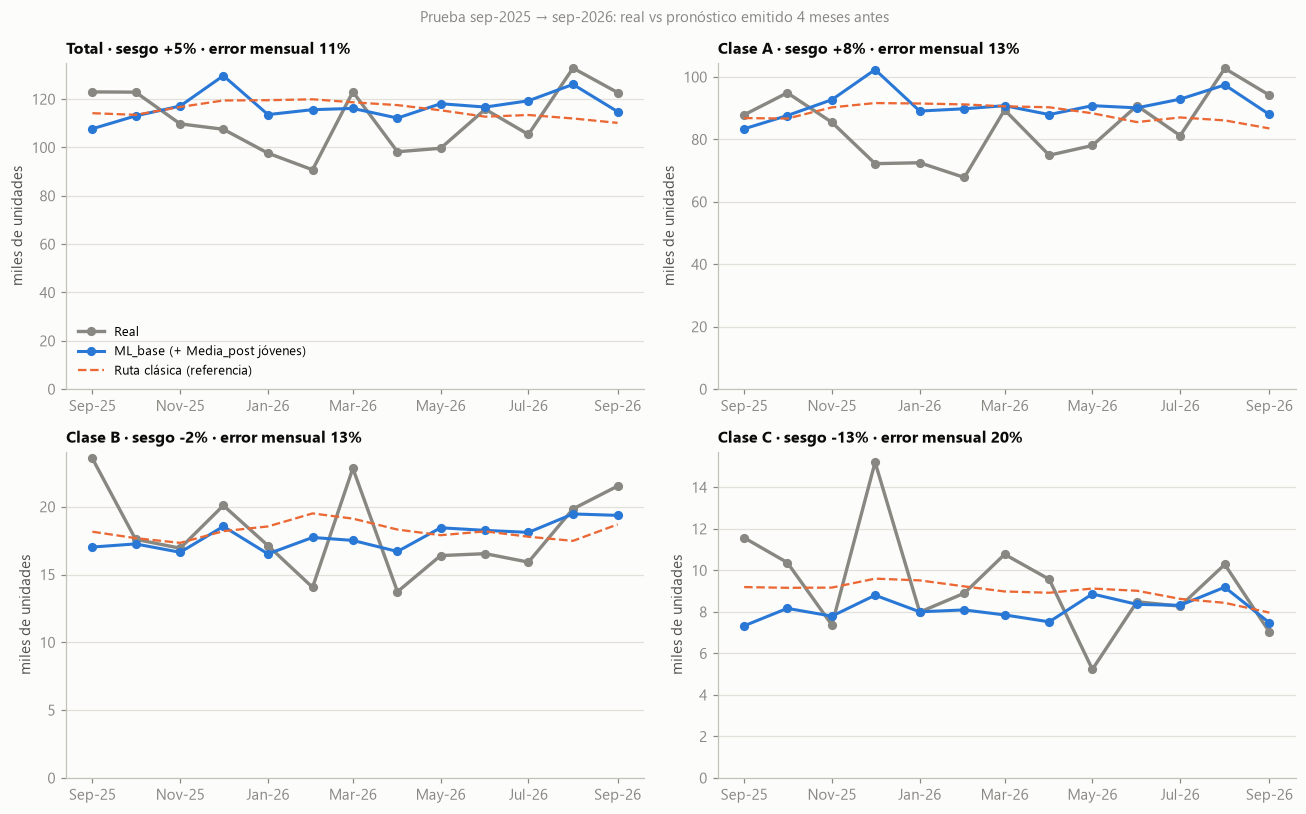

Miles de unidades; dif_ML = pronóstico / real − 1
         Total                Clase A                Clase B                Clase C               
             y ML_base dif_ML       y ML_base dif_ML       y ML_base dif_ML       y ML_base dif_ML
mes_obj                                                                                           
Sep-25   123.0   107.7   -12%    87.9    83.4    -5%    23.6    17.0   -28%    11.6     7.3   -37%
Oct-25   122.9   113.1    -8%    94.9    87.6    -8%    17.6    17.3    -2%    10.4     8.2   -21%
Nov-25   109.8   117.1    +7%    85.5    92.7    +8%    16.9    16.6    -2%     7.4     7.8    +6%
Dec-25   107.5   129.7   +21%    72.2   102.3   +42%    20.1    18.5    -8%    15.2     8.8   -42%
Jan-26    97.6   113.6   +16%    72.5    89.1   +23%    17.1    16.5    -4%     8.0     8.0    +0%
Feb-26    90.8   115.6   +27%    67.8    89.8   +32%    14.1    17.7   +26%     8.9     8.1    -9%
Mar-26   123.0   116.2    -6%    89.4    90.8    +2%    22.

In [11]:
jov = pd.read_parquet(RES / "cold_jovenes_prueba.parquet")[["id_articulo", "origen", "mes_obj", "y", "Media_post"]]
sis = pd.concat([test[["id_articulo", "origen", "mes_obj", "y", "ML_base", "Ruta_clasica"]],
                 jov.assign(ML_base=jov.Media_post, Ruta_clasica=jov.Media_post).drop(columns="Media_post")])
abc_mov = pd.read_parquet(RAIZ / "data" / "processed" / "segmentacion_sku_mes.parquet", columns=["id_articulo", "mes", "abc_movil"])
sis = sis.merge(abc_mov.rename(columns={"mes": "origen"}), on=["id_articulo", "origen"], how="left")

fig, ax = plt.subplots(2, 2, figsize=(12, 7.5))
tablas = {}
for a, (tit, x) in zip(ax.ravel(), [("Total", sis)] + [(f"Clase {c}", sis[sis.abc_movil == c]) for c in "ABC"]):
    g = x.groupby("mes_obj")[["y", "ML_base", "Ruta_clasica"]].sum() / 1e3
    a.plot(g.index, g.y, lw=2.2, marker="o", ms=5, color=GRIS, label="Real")
    a.plot(g.index, g.ML_base, lw=2, marker="o", ms=5, color=AZUL, label="ML_base (+ Media_post jóvenes)")
    a.plot(g.index, g.Ruta_clasica, lw=1.5, ls="--", color=COLORES[1], label="Ruta clásica (referencia)")
    sesgo = g.ML_base.sum() / g.y.sum() - 1
    err = (g.ML_base - g.y).abs().sum() / g.y.sum()
    a.set_title(f"{tit} · sesgo {sesgo:+.0%} · error mensual {err:.0%}", fontsize=10.5)
    a.set_ylim(0, None)
    a.set_ylabel("miles de unidades")
    a.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b-%y"))
    tablas[tit] = g.assign(dif_ML=g.ML_base / g.y - 1)
ax[0, 0].legend(fontsize=8.5, loc="lower left")
fig.suptitle("Prueba sep-2025 → sep-2026: real vs pronóstico emitido 4 meses antes", fontsize=10, color=GRIS)
fig.tight_layout()
fig.savefig(FIG / "25_real_vs_pronostico_prueba.png"); plt.show()

t = pd.concat({k: v[["y", "ML_base", "dif_ML"]] for k, v in tablas.items()}, axis=1)
t.index = t.index.strftime("%b-%y")
fmt = t.copy()
for c in fmt.columns:
    fmt[c] = t[c].map(lambda v: f"{v:+.0%}" if c[1] == "dif_ML" else f"{v:.1f}")
print("Miles de unidades; dif_ML = pronóstico / real − 1")
print(fmt.to_string())

**Lectura.** El total queda **+5 %** en el año, con un error mensual del 11 %: a nivel agregado los errores de los SKUs
se compensan. El pronóstico es mucho **más plano** que la venta real (108–130 contra 91–133 mil u./mes): a 4 meses
capta el nivel y algo de estacionalidad, pero no los picos de cada mes, que se cubren con el SS (`03_inventario`).
El error más grande es el **sesgo de dic-2025 a feb-2026 en la clase A** (+42 %, +23 %, +32 %): el modelo repitió
un repunte estacional que este año no ocurrió (LOG #23). Al inicio (sep–oct 2025) queda 8–12 % abajo, porque la
venta se recuperó más rápido del destock de 2024. En C sub-pronostica (−13 %) y no capta los pedidos grandes y
esporádicos (dic-2025: 15 mil reales contra 9 mil), típicos de la demanda grumosa.

### 4.3 XGBoost por serie, top 30 SKUs y top 30 familias (`notebooks/XGBoost.py`, LOG #33)

Adaptación del script de XGBoost del usuario: un `XGBRegressor` por serie (100 árboles, profundidad 3, error
cuadrático), con features = mes + 3 lags. Con h = 4 los lags son 4, 5 y 6. Los datos vienen del panel (`order_date`,
`Venta Producto`). Top 30 por unidades del último año. Se evalúa con el **mismo walk-forward** (entrena con datos
≤ T, pronostica T + 4) y se compara contra los nuestros (`src/comparar_xgb.py`):
- **SKU:** pares (SKU, origen) del set evaluado.
- **Familia:** real = total de la familia. Lo nuestro se suma por familia: maduros + jóvenes (`Media_post`).

MAE y RMSE están en unidades; R² fuera de muestra = 1 − SSE / SST de los reales del periodo.

In [12]:
import comparar_xgb as cx

XG = cx.NUESTROS + ["XGBoost"]
sku = cx.nivel_sku()
fam, _ = cx.nivel_familia()
for nivel, res in [("Top 30 SKUs", sku), ("Top 30 familias", fam)]:
    for p, d in res.items():
        print(f"\n{nivel} · {p} ({d.id_articulo.nunique()} series, {len(d)} pares serie-origen)")
        print(cx.tabla(d, XG).sort_values("MASE").round(3).to_string())

ins = pd.concat([pd.read_csv(RES / f"xgb_top30_insample_{n}.csv") for n in ("sku", "familia")])
print("\nXGBoost in-sample (como el script original): mediana por nivel")
print(ins.groupby("nivel")[["R2", "wMAPE", "sMAPE"]].median().round(3).to_string())


Top 30 SKUs · validacion (30 series, 360 pares serie-origen)
               MASE   WAPE  sesgo       MAE      RMSE  sMAPE     R2
Ruta_clasica  0.818  0.324  0.052   670.746   998.098  0.365  0.633
TD_mix_k3     0.853  0.334  0.042   691.237  1042.334  0.366  0.600
ML_base       0.874  0.347  0.075   718.460  1091.291  0.376  0.561
MA12          0.885  0.352  0.095   729.044  1104.410  0.378  0.550
XGBoost       0.938  0.385  0.106   797.462  1213.484  0.404  0.457
SNaive        1.202  0.490  0.159  1015.106  1656.708  0.469 -0.012

Top 30 SKUs · prueba (30 series, 390 pares serie-origen)
               MASE   WAPE  sesgo      MAE      RMSE  sMAPE     R2
Ruta_clasica  0.971  0.404  0.037  787.352  1226.254  0.436  0.372
MA12          0.972  0.402  0.047  783.253  1221.962  0.434  0.377
TD_mix_k3     0.984  0.411  0.068  800.035  1259.571  0.434  0.338
ML_base       0.996  0.415  0.067  809.373  1262.568  0.439  0.334
SNaive        1.115  0.464  0.060  904.113  1447.022  0.472  0.126
XG


XGBoost in-sample (como el script original): mediana por nivel
            R2  wMAPE  sMAPE
nivel                       
familia  0.877  0.100  0.111
sku      0.896  0.123  0.154


**Lectura.**
- **XGBoost por serie queda último o penúltimo** en los dos niveles, empatado con SNaive. En los top 30 SKUs su
  MASE es 0.938 en validación y 1.116 en prueba, contra 0.82–0.87 y 0.97–1.0 de los nuestros. En las familias
  queda en 1.09 y 1.06, contra 0.80–0.91. Además sobre-pronostica más (+11 a +19 %).
- **El R² in-sample engaña.** Ajustado sobre su propia historia, como en el script original, da un R² mediano de
  0.9 y un wMAPE de 10–13 %. Fuera de muestra, el R² de los SKUs cae a 0.46 en validación y a −0.05 en prueba. Un
  modelo de 100 árboles por serie, con unos 100 meses de datos, **memoriza** la historia en lugar de aprender un
  patrón que se repita. Por eso todo se evalúa con walk-forward.
- La diferencia no es XGBoost contra HistGradientBoosting (son el mismo tipo de algoritmo). Es **un modelo por
  serie contra uno global**: el global aprende de ~800 SKUs a la vez, con features normalizadas y pérdida Poisson.
- **En los 30 SKUs más grandes, los clásicos están a la par del ML:** la ruta clásica (0.818) y MA12 son tan buenos
  o mejores que `ML_base`. Es coherente con lo visto en MAE por ABC: la ventaja del ML está en la cola de SKUs
  chicos e intermitentes. `TD_mix` mejora a `ML_base` en los top SKUs en ambos periodos.

### 4.4 Top 30: real contra cada pronóstico, y qué mide realmente el R²

**Qué es el R².** R² = 1 − SSE / SST, donde SSE = Σ(pronóstico − real)² y SST = Σ(real − media del real)².
Compara el modelo contra un pronóstico "tonto": **una línea constante en la media real del periodo**.
- R² = 1: error cero. R² = 0: igual que esa línea constante. **R² < 0: peor que la línea constante.**
- Esa línea es tramposa, porque usa la media **real** del periodo, que no se conoce de antemano. Un R² negativo
  fuera de muestra no es raro en pronóstico: ganarle a la media real de un futuro que no has visto es difícil.

**Por qué el R² del script original salía tan alto (~0.9).**
1. **In-sample:** el modelo se evaluaba sobre los mismos meses con que se entrenó. Con 100 árboles de profundidad 3
   y ~100 meses por serie, el modelo puede aprenderse cada pico de memoria. El R² mide memoria, no pronóstico.
2. **Con lags 1–3 (horizonte 1),** el mes anterior explica mucho. A 4 meses de distancia esa información no existe.

**Por qué el R² agrupado de varias series engaña.** Si se juntan series de distinto tamaño (un SKU de 5,000 u./mes
con uno de 500), casi toda la varianza (SST) está **entre** series, no dentro de cada una. Cualquier pronóstico
que adivine el tamaño de cada SKU obtiene un R² alto aunque no capte ningún movimiento mes a mes. La tabla de
abajo lo mide con un **oráculo** que predice, para cada serie, su propia media real del periodo (una constante): ese
oráculo saca un R² agrupado alto, pero 0 dentro de cada serie por definición. Por eso las familias (tamaños muy
distintos) tenían R² de 0.82–0.87 y los SKUs del top 30 (tamaños más parecidos) solo 0.3–0.6.

**El R² por serie** (dentro de cada SKU, sobre los 12–13 meses del periodo) dice cuánto del movimiento mes a mes
explica el pronóstico. A 4 meses suele ser ≤ 0: los pronósticos son mucho más planos que la venta real (sección 4.2),
y los picos se cubren con stock de seguridad, no con el pronóstico. Por esto el proyecto decide con **MASE + sesgo**:
el MASE compara contra un benchmark que sí se conoce de antemano (el seasonal naive in-sample), no se infla por el
tamaño de las series y no eleva al cuadrado los picos.

In [13]:
MOD30 = ["TD_mix_k3", "ML_base", "Ruta_clasica", "MA12", "SNaive", "XGBoost"]
for nivel, res in [("Top 30 SKUs", sku), ("Top 30 familias", fam)]:
    for p, d in res.items():
        print(f"\n{nivel} · {p}")
        print(cx.r2_descompuesto(d, MOD30).round(3).to_string())


Top 30 SKUs · validacion
              R2_agrupado  R2_por_serie_mediana  %_series_R2<0
TD_mix_k3           0.600                -0.356          0.867
ML_base             0.561                -0.260          1.000
Ruta_clasica        0.633                -0.160          0.933
MA12                0.550                -0.285          1.000
SNaive             -0.012                -1.536          1.000
XGBoost             0.457                -0.744          1.000
oráculo             0.715                 0.000          0.000

Top 30 SKUs · prueba


              R2_agrupado  R2_por_serie_mediana  %_series_R2<0
TD_mix_k3           0.338                -0.168          0.900
ML_base             0.334                -0.258          0.867
Ruta_clasica        0.372                -0.129          0.967
MA12                0.377                -0.148          0.833
SNaive              0.126                -0.669          0.933
XGBoost            -0.051                -0.562          0.867
oráculo             0.475                 0.000          0.000

Top 30 familias · validacion


              R2_agrupado  R2_por_serie_mediana  %_series_R2<0
TD_mix_k3           0.868                -0.622          0.900
ML_base             0.841                -0.520          1.000
Ruta_clasica        0.877                -0.303          0.967
MA12                0.843                -0.472          1.000
SNaive              0.576                -1.598          0.933
XGBoost             0.738                -1.249          1.000
oráculo             0.922                 0.000          0.000

Top 30 familias · prueba
              R2_agrupado  R2_por_serie_mediana  %_series_R2<0
TD_mix_k3           0.868                -0.210          0.833
ML_base             0.863                -0.233          0.833
Ruta_clasica        0.871                -0.169          0.900
MA12                0.867                -0.187          0.833
SNaive              0.812                -0.901          0.967
XGBoost             0.820                -0.845          0.967
oráculo             0.894    

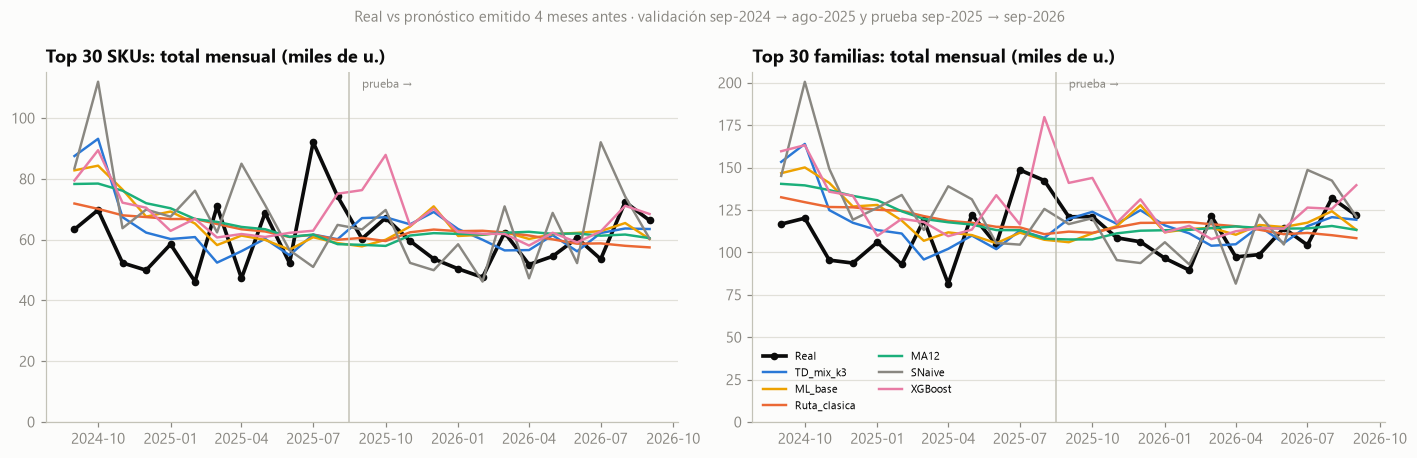

In [14]:
COL30 = dict(zip(MOD30, [AZUL, COLORES[3], COLORES[1], COLORES[2], GRIS, COLORES[4]]))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, (nivel, res) in zip(ax, [("Top 30 SKUs", sku), ("Top 30 familias", fam)]):
    d = pd.concat(res.values())
    tot = d.groupby("mes_obj")[["y"] + MOD30].sum() / 1e3
    a.plot(tot.index, tot.y, color="#0b0b0b", lw=2.4, marker="o", ms=4, label="Real")
    for m in MOD30:
        a.plot(tot.index, tot[m], color=COL30[m], lw=1.6, label=m)
    a.axvline(pd.Timestamp("2025-08-16"), color=GRIS_CLARO, lw=1)
    a.text(pd.Timestamp("2025-09-01"), a.get_ylim()[1] * .98, "prueba →", fontsize=8, color=GRIS, va="top")
    a.set_ylim(0, None)
    a.set_title(f"{nivel}: total mensual (miles de u.)")
ax[1].legend(fontsize=7.5, ncol=2, loc="lower left")
fig.suptitle("Real vs pronóstico emitido 4 meses antes · validación sep-2024 → ago-2025 y prueba sep-2025 → sep-2026",
             fontsize=9.5, color=GRIS)
fig.tight_layout()
fig.savefig(FIG / "26_top30_total.png"); plt.show()

Por SKU (los 30, ordenados por venta del último año). Para que se lea, cada panel muestra el real, el modelo elegido
(`TD_mix_k3`), la ruta clásica y XGBoost; los demás están en la tabla y en el CSV. La escala vertical es propia de
cada panel.

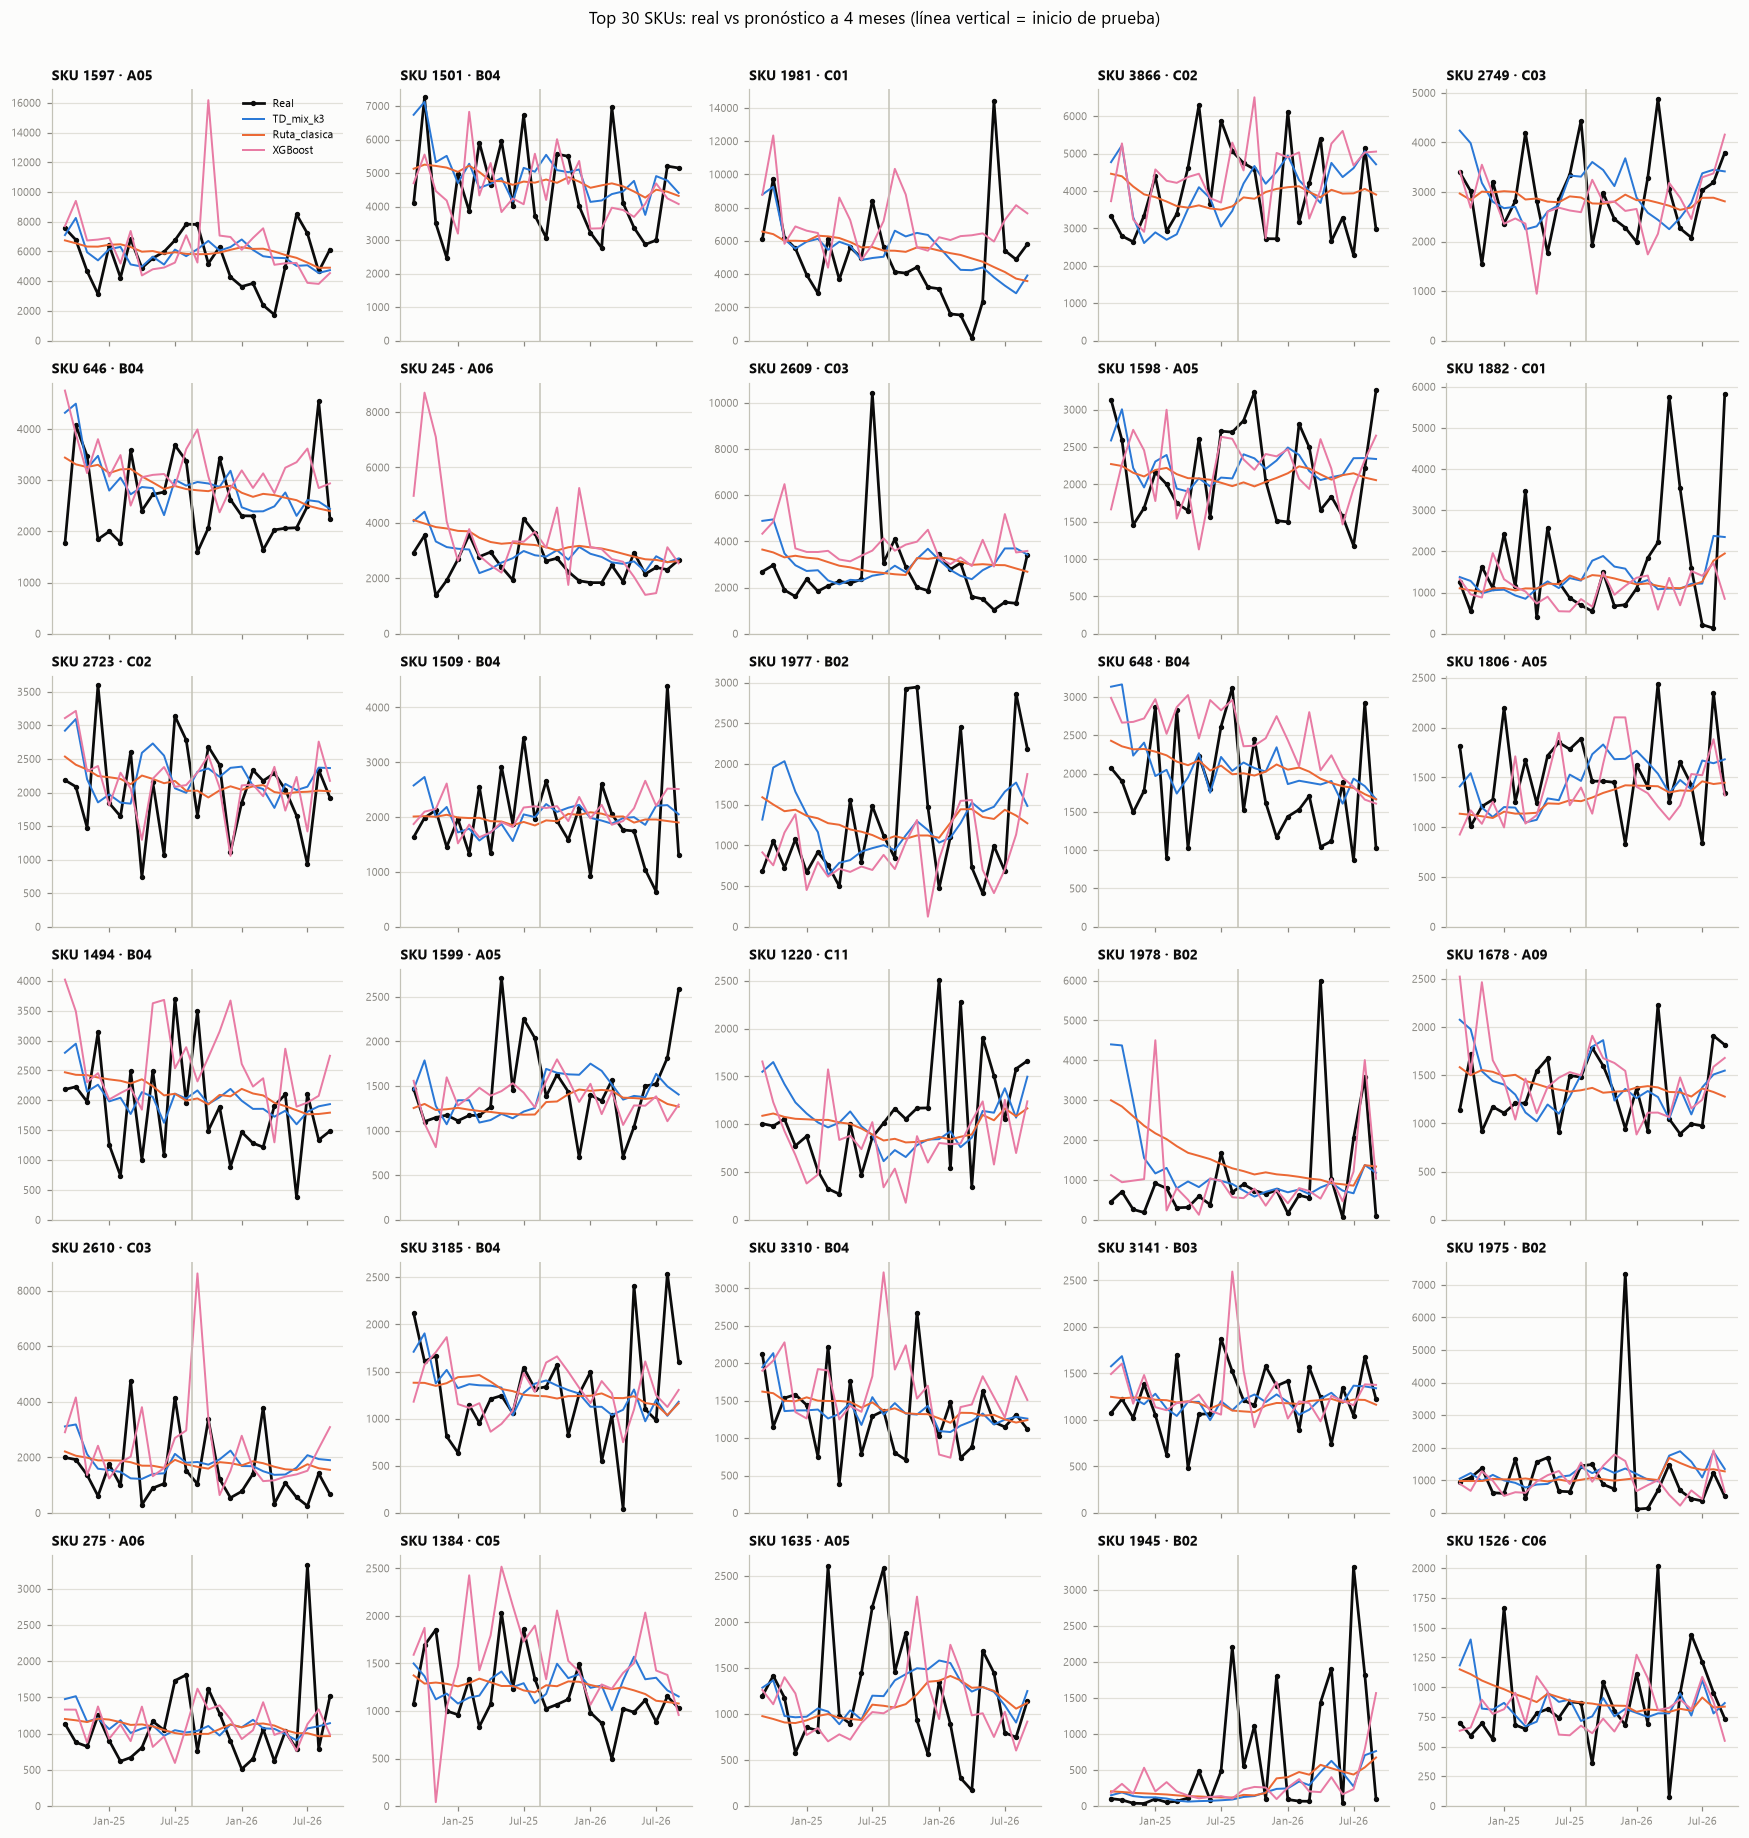

In [15]:
d = pd.concat(sku.values())
orden = d[d.mes_obj >= "2025-10-01"].groupby("id_articulo").y.sum().sort_values(ascending=False).index
fig, ax = plt.subplots(6, 5, figsize=(16, 17), sharex=True)
for a, s in zip(ax.ravel(), orden):
    g = d[d.id_articulo == s].sort_values("mes_obj")
    a.plot(g.mes_obj, g.y, color="#0b0b0b", lw=1.8, marker="o", ms=2.5, label="Real")
    for m in ["TD_mix_k3", "Ruta_clasica", "XGBoost"]:
        a.plot(g.mes_obj, g[m], color=COL30[m], lw=1.3, label=m)
    a.axvline(pd.Timestamp("2025-08-16"), color=GRIS_CLARO, lw=1)
    a.set_ylim(0, None)
    a.set_title(f"SKU {s} · {g.familia.iloc[0]}", fontsize=9)
    a.tick_params(labelsize=7)
    a.xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator(bymonth=[1, 7]))
    a.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b-%y"))
ax[0, 0].legend(fontsize=7)
fig.suptitle("Top 30 SKUs: real vs pronóstico a 4 meses (línea vertical = inicio de prueba)", fontsize=11)
fig.tight_layout(rect=[0, 0, 1, .975])
fig.savefig(FIG / "27_top30_por_sku.png"); plt.show()

**Cuánto predijo cada modelo para cada SKU en el año de prueba** (sep-2025 → sep-2026, 13 meses; unidades
totales del periodo). La columna `mejor` es el modelo con menor error absoluto mensual acumulado del SKU, no el más
cercano en el total: un modelo puede acertar el total del año compensando errores de meses distintos. El detalle
mes a mes de ambos periodos queda en `reports/top30_real_vs_pronosticos.csv`.

In [16]:
det = pd.concat(sku, names=["periodo"]).reset_index(level=0)[["periodo", "id_articulo", "familia", "origen", "mes_obj", "y"] + MOD30]
det.round(1).to_csv(RAIZ / "reports" / "top30_real_vs_pronosticos.csv", index=False, encoding="utf-8-sig")

pr = sku["prueba"]
tot = pr.groupby("id_articulo")[["y"] + MOD30].sum().reindex(orden)
mae = pr.assign(**{m: (pr[m] - pr.y).abs() for m in MOD30}).groupby("id_articulo")[MOD30].sum().reindex(orden)
tot.insert(0, "familia", pr.groupby("id_articulo").familia.first().reindex(orden))
tot["mejor"] = mae.idxmin(axis=1)
tot.loc["TOTAL"] = ["", *tot[["y"] + MOD30].sum(), ""]
out = tot.copy()
for m in ["y"] + MOD30:
    out[m] = tot[m].map(lambda v: f"{v:,.0f}")
for m in MOD30:
    out[f"{m} %"] = (tot[m].astype(float) / tot.y.astype(float) - 1).map(lambda v: f"{v:+.0%}")
out = out.rename(columns={"y": "real"})
out.round(0).to_csv(RAIZ / "reports" / "top30_totales_prueba.csv", encoding="utf-8-sig")
print(out[["familia", "real"] + MOD30 + ["mejor"]].to_string())
print()
print("Diferencia del total del año vs real:")
print(out[[f"{m} %" for m in MOD30]].to_string())
print()
print("SKUs donde cada modelo es el mejor (menor Σ|error| mensual):", tot.mejor.iloc[:-1].value_counts().to_dict())

            familia     real TD_mix_k3  ML_base Ruta_clasica     MA12   SNaive  XGBoost         mejor
id_articulo                                                                                          
1597            A05   66,633    74,314   76,284       74,673   73,296   78,436   83,812          MA12
1501            B04   54,790    60,509   59,986       59,592   61,051   60,191   55,568       XGBoost
1981            C01   55,101    62,993   63,636       63,323   63,593   73,003   90,511          MA12
3866            C02   50,031    57,993   57,737       51,532   53,769   53,060   61,655  Ruta_clasica
2749            C03   37,214    39,505   38,207       36,361   37,744   37,716   37,375          MA12
646             B04   31,388    34,396   34,144       34,827   34,817   35,073   40,203       ML_base
245             A06   29,967    35,290   35,388       37,815   35,055   36,515   36,718          MA12
2609            C03   30,403    39,905   38,925       38,747   39,568   39,832   4

## 5. Cold start (`src/cold_start.py`, LOG #24)

Lo que queda fuera del set maduro, en dos segmentos:
- **Jóvenes** (0–11 meses de vida en el origen): baselines simples contra un modelo global propio (`ML_joven`).
  Sin 12 meses de historia no hay MASE: se mide WAPE, sesgo y error en log. Misma regla de adopción (#20), con
  WAPE en lugar de MASE.
- **Pre-lanzamiento** (lanzan entre T+1 y T+4): regla de análogos (familia → sublínea → banda de precio) con rango
  p25–p75 / p10–p90. Supone que el lanzamiento se conoce por comercial.

In [17]:
import cold_start as cs
jv = {p: pd.read_parquet(RES / f"cold_jovenes_{p}.parquet") for p in ["validacion", "prueba"]}
MJ = cs.BASELINES + ["ML_joven"]
FMTJ = {"WAPE": "{:.3f}", "sesgo": "{:+.1%}", "MAE_log": "{:.3f}", "WAPE_total": "{:.1%}", "sesgo_total": "{:+.1%}"}
for p, d in jv.items():
    print(f"{p}: {len(d):,} filas · {d.id_articulo.nunique()} SKUs · {d.y.sum():,.0f} u.")
pd.concat({p: cs.resumen_joven(d, MJ) for p, d in jv.items()}, axis=1).style.format(
    {(p, c): f for p in jv for c, f in FMTJ.items()})

validacion: 1,195 filas · 182 SKUs · 24,330 u.
prueba: 1,267 filas · 188 SKUs · 29,148 u.


In [18]:
def wape_origen(d):
    return pd.DataFrame({o: g[MJ].sub(g.y, axis=0).abs().sum() / g.y.sum() for o, g in d.groupby("origen")}).T
for p, d in jv.items():
    w = wape_origen(d)
    print(f"{p}: mejor modelo por origen →", w.idxmin(axis=1).value_counts().to_dict())
wv = wape_origen(jv["validacion"])
rv = cs.resumen_joven(jv["validacion"], MJ).WAPE
mejor_base = rv[cs.BASELINES].idxmin()
adopta_ml = (rv["ML_joven"] <= rv[mejor_base] - .01) and ((wv.ML_joven < wv[mejor_base]).mean() >= 2 / 3)
modelo_joven = "ML_joven" if adopta_ml else mejor_base
print(f"\nMejor baseline en validación: {mejor_base} · ¿ML_joven cumple la regla?: {adopta_ml} → modelo: {modelo_joven}")

validacion: mejor modelo por origen → {'Media_post': 8, 'ML_joven': 4}
prueba: mejor modelo por origen → {'ML_joven': 6, 'Media_post': 5, 'Curva_analogos': 2}

Mejor baseline en validación: Media_post · ¿ML_joven cumple la regla?: False → modelo: Media_post


In [19]:
d = jv["prueba"].assign(tramo=lambda x: pd.cut(x.edad, [0, 3, 6, 12], labels=["1–3 m", "4–6 m", "7–12 m"]))
print("Prueba por edad en el origen (WAPE; peso = % de unidades del segmento):")
r = pd.concat({t: cs.resumen_joven(g, MJ).WAPE for t, g in d.groupby("tramo", observed=True)}, axis=1)
print(pd.concat([r, (d.groupby("tramo", observed=True).y.sum() / d.y.sum()).rename("peso").to_frame().T]).round(3).to_string())

Prueba por edad en el origen (WAPE; peso = % de unidades del segmento):


                1–3 m  4–6 m  7–12 m
Media_post      1.081  0.771   0.759
Escala          1.217  0.788   0.801
Analogos        1.152  0.801   0.842
Curva_analogos  1.289  0.914   0.804
ML_joven        0.839  0.794   0.792
peso            0.153  0.222   0.625


In [20]:
pre = {p: pd.read_parquet(RES / f"cold_prelanz_{p}.parquet") for p in ["validacion", "prueba"]}
print(pd.DataFrame({p: cs.resumen_prelanz(d) for p, d in pre.items()}).round(3).to_string())
print("\nCobertura nominal: p25–p75 = 50 %, p10–p90 = 80 %.")

                   validacion    prueba
filas                 457.000   263.000
SKUs                  143.000    92.000
unidades             6742.000  3863.000
WAPE                    1.439     2.225
sesgo                   0.328     1.107
cobertura_p25_p75       0.621     0.487
cobertura_p10_p90       0.825     0.741

Cobertura nominal: p25–p75 = 50 %, p10–p90 = 80 %.


## 6. Hallazgos

**Modelo elegido: `TD_mix_k3`** (desde el 24-oct, LOG #32): el `ML_base` (HistGradientBoosting Poisson global con
hiperparámetros C, features base y limpieza causal de outliers) reconciliado con el nivel × índice estacional de su
familia. Los puntos 1–9 comparan `ML_base` contra los clásicos; el 10 y el 11 son los experimentos posteriores.

1. **El modelo global gana a todo lo clásico, y de forma consistente.** En validación su MASE es 0.744, contra 0.784
   de la ruta clásica y 1.03 de SNaive. En prueba es 0.826, contra 0.882 y 1.03. Le gana a la ruta clásica en 10 de
   12 orígenes de validación y en 11 de 13 de prueba. Entre los clásicos, el mejor en prueba es **MA12** (0.855):
   un nivel de 12 meses aguanta mejor el periodo posterior al escalón que modelos más reactivos como ETS o Croston.
2. **Dónde gana más:** en las series intermitentes y grumosas (validación: 0.58 y 0.59 frente a 0.84 y 0.70 de TSB)
   y en los SKUs B, C y mixtos. En las series **suaves** (59 % de las unidades de prueba), el ML y SBA quedan casi
   empatados: en validación ganó SBA (0.792 vs 0.807) y en prueba el ML (0.913 vs 0.952). No vale la pena
   complicarlo con un híbrido por segmento.
3. **Ablaciones** (regla de adopción en LOG #20):
   - **Limpieza de outliers: se queda.** Sin ella el MASE empeora en validación (+0.004) y en prueba (+0.006), y
     también empeoran el WAPE total y el sesgo.
   - **Proxy de sobre-stock: no se adopta por ahora, aunque la evidencia es mixta.** En validación empeora (de +0.009
     a +0.017). En prueba, la versión SKU + agregado mejora un poco (−0.009, gana en 8 de 13 orígenes y baja el
     sesgo total 2.2 pp). Es coherente con que la señal de destock pese más después del escalón de 2024, pero no
     pasa la regla. El código queda y se reevalúa en cada reentrenamiento.
   - **Tasa de devoluciones rezagada: ruido.** Mejora 0.005 en validación (7 de 12 orígenes) y empeora 0.004 en
     prueba. No se adopta.
   - **Hiperparámetros:** C (0.744), A (0.751) y B (0.762) quedan muy cerca. El modelo no es sensible a ellos.
4. **El sesgo es positivo en todos los modelos** (se sobre-pronostica): ML +10 % en validación y +5 % en prueba.
   Viene del ajuste de nivel posterior al escalón de 2024, que todos aprenden tarde. Por mes, el error se concentra
   en **dic–feb** (+17 a +28 % en el total): a 4 meses de distancia, el modelo no anticipa lo bajos que quedaron
   ene–feb 2026. Esto importa para la fase de pedidos: un sesgo de +5 a +10 % equivale a inventario de más.
5. **En el total de la compañía los modelos quedan parejos.** El WAPE total en prueba va de 10.5 % (SNaive) a
   10.7 % (MA12) y 11.3 % (ML). La ventaja del ML está a nivel SKU, que es donde se decide el pedido. Para el total
   mensual, SNaive o MA12 son igual de buenos.
6. **Cobertura:** el set evaluado (SKUs con ≥ 13 meses de historia) cubre en mediana el 97.8 % de las unidades de
   cada mes objetivo. El cold start (alrededor del 2 %) queda pendiente de una regla propia, por ejemplo por familia
   o por SKU análogo.
7. **Caveat:** el MAPE (más de 190 %) no sirve en esta cartera. Las métricas de decisión son MASE/RMSSE y sesgo.
8. **Cold start, SKUs jóvenes: gana lo simple.** `Media_post` (media desde el lanzamiento, sin el mes 0) tiene el
   mejor WAPE en validación (0.874 vs 0.937 del ML) y es el mejor en 8 de 12 orígenes. En prueba el ML queda apenas
   adelante (0.799 vs 0.811). Por la regla #20 se adopta **`Media_post`**. Con ~180 SKUs por periodo, la historia
   corta no le alcanza al ML para superar al baseline.
   - Tiene un **sesgo de −21 % a −25 %**: los SKUs jóvenes siguen en rampa y la media de sus primeros meses se
     queda corta. El ML y la curva de análogos corrigen parte del sesgo (−5 a −12 %), pero con más error por SKU.
     Para pedidos, conviene tratar este sub-pronóstico como un riesgo de quiebre de stock.
   - Los priors de análogos con **mediana** sub-pronosticaban un 70–76 %: con 23 % de lanzamientos fallidos, la
     curva "típica" es casi cero. Para volumen se usa la media; los cuantiles solo sirven para el rango.
9. **Cold start, pre-lanzamiento: solo rango, no número.** El punto de los análogos falla por mucho (WAPE de 144 a
   223 %), pero los rangos están razonablemente calibrados: p10–p90 cubre el 82 % y el 74 % (nominal 80 %).
   **No existe plan de lanzamientos**, así que no hay pronóstico por SKU antes de su primera venta. Desde su
   lanzamiento el SKU entra al segmento de jóvenes. El rango de análogos queda como guía opcional para SKUs del
   catálogo con `SeCompra = 1` y sin ventas (LOG #24).
10. **Jerárquico middle-out (3.3): se adopta `TD_mix_k3`.** Pronosticar la familia con nivel × índice y repartirla
    con el ML (`TD_ML`) da el mejor MASE de validación (0.721), pero gana solo en 7 de 12 orígenes y empeora en
    prueba (0.838). Lo que sí cumple la regla #20 es **promediar** el volumen de la familia con la suma del ML
    (`TD_mix`: 0.726, 9 de 12 orígenes). En prueba empata con `ML_base` (0.827 vs 0.826). La ganancia es sobre todo
    de sesgo (el nivel de 3 meses se adapta rápido a la caída de 2024–25), y en inventario ahorra 4–5 % de stock a
    igual fill (`03_inventario`).
11. **XGBoost por serie (4.3): no se adopta.** En los top 30 SKUs y en las top 30 familias queda al nivel de SNaive
    fuera de muestra, aunque in-sample parezca excelente (R² ~0.9). Confirma que lo que funciona aquí es el modelo
    **global**, no el algoritmo de boosting en sí.